# 07 · Closing the loop

In the previous notebooks every filter replayed a **recorded run**: the commands had already
been chosen, and the filter only had to work out where the robot was. That is how filters are
compared (same data for all), and how one works with the log of a real robot.

On a real robot the filter is **in the loop**. At every step

1. the controller looks at the filter's current estimate and chooses the next command,
2. the robot moves (with noise) and its sensors read,
3. the filter is updated.

The command is computed from the *estimate*, never from the true pose, which the robot does
not have. A wrong estimate becomes a wrong command, and the robot leaves its path.

The task here is the one a robot lawnmower actually has: drive along parallel stripes.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))

import numpy as np
import matplotlib.pyplot as plt
from bayesian_filters import (World, CompassGpsKF, EKF, UKF, ParticleFilter, DeadReckoning,
                              PathFollower, stripes_path, distance_to_path, simulate_closed_loop,
                              motion_model, position_error, position_rmse)
from bayesian_filters import viz
viz.style()

world = World.default()
waypoints = stripes_path(world)            # the planned path: stripes 40 units apart
x0 = (waypoints[0, 0], waypoints[0, 1], 0.0)  # start at the first corner, facing along the stripe
P0 = np.diag([1.0, 1.0, 0.01])
print(f"{len(waypoints)} waypoints, path length {PathFollower(waypoints).length:.0f} units")

14 waypoints, path length 2060 units


## 1. The controller

`PathFollower` is a small "pure pursuit" controller. Given a pose, it finds where that pose is
along the path, aims at the point `lookahead` units further on, and commands a turn towards it
(limited to `max_turn`) followed by one step.

Give it the true pose and no noise, and the robot follows the stripes, cutting the corners a
little:

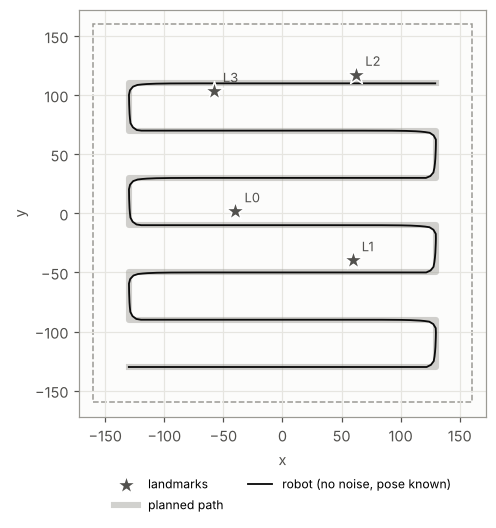

500 steps, largest distance to the path 3.1


In [2]:
ctl = PathFollower(waypoints)
x = np.array(x0)
path = [x]
while not ctl.done:
    u = ctl(x)                 # here the controller is given the exact pose
    if ctl.done:
        break
    x = motion_model(x, u)     # and the motion has no noise
    path.append(x)
path = np.array(path)

fig, ax = plt.subplots(figsize=(4.8, 4.8))
viz.plot_world(ax, world)
ax.plot(waypoints[:, 0], waypoints[:, 1], color=viz.MUTED, lw=4, alpha=0.45, label="planned path")
ax.plot(path[:, 0], path[:, 1], color=viz.INK, lw=1.2, label="robot (no noise, pose known)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8)
plt.show()
print(f"{len(path) - 1} steps, largest distance to the path {distance_to_path(path, waypoints).max():.1f}")

## 2. Dead reckoning in the loop

Now the real situation: the motion is noisy and the controller only gets an estimate.
`simulate_closed_loop(world, filter, controller, ...)` runs the loop described above and returns
the run that was produced and the filter's estimates.

First with `DeadReckoning`, a "filter" that integrates the commands and never looks at a sensor.
The robot *believes* it is following the stripes perfectly.

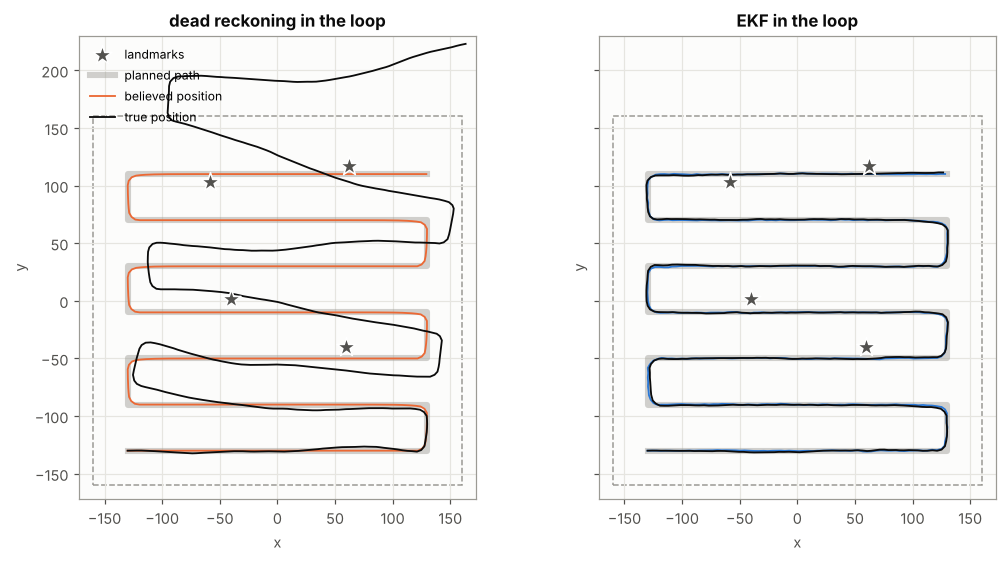

dead reckoning  distance from the true position to the planned path: RMS  36.0, max  117.8
EKF             distance from the true position to the planned path: RMS   0.8, max    3.7


In [3]:
def show(ax, run, res, name):
    viz.plot_world(ax, world, label_landmarks=False)
    ax.plot(waypoints[:, 0], waypoints[:, 1], color=viz.MUTED, lw=4, alpha=0.45, label="planned path")
    ax.plot(res.means[:, 0], res.means[:, 1], color=viz.color(name), lw=1.2, label="believed position")
    ax.plot(run.truth[:, 0], run.truth[:, 1], color=viz.INK, lw=1.2, label="true position")
    ax.set_ylim(-world.half_height - 12, world.half_height + 70)

run_dr, res_dr = simulate_closed_loop(world, DeadReckoning.from_world(world, x0, P0),
                                      PathFollower(waypoints), n_steps=700, x0=x0, seed=1)
run_ekf, res_ekf = simulate_closed_loop(world, EKF.from_world(world, x0, P0),
                                        PathFollower(waypoints), n_steps=700, x0=x0, seed=1)

fig, axes = plt.subplots(1, 2, figsize=(10, 5.2), sharey=True)
show(axes[0], run_dr, res_dr, "UKF"); axes[0].set_title("dead reckoning in the loop")
show(axes[1], run_ekf, res_ekf, "EKF"); axes[1].set_title("EKF in the loop")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

for name, run in [("dead reckoning", run_dr), ("EKF", run_ekf)]:
    d = distance_to_path(run.truth, waypoints)
    print(f"{name:15s} distance from the true position to the planned path: "
          f"RMS {np.sqrt(np.mean(d**2)):5.1f}, max {d.max():6.1f}")

The believed path of dead reckoning lies exactly on the plan: the controller corrects the only
error it can see, which is zero. The true robot drifts away and ends outside the lawn. With the
EKF in the loop the estimate follows the truth, so correcting the estimate corrects the robot.

There are now **two** errors to look at:

* the *estimation error*: believed position minus true position (the filter's job);
* the *cross-track error*: distance from the true position to the planned path (what matters
  for the lawn). It is small only if the estimate is good *and* the controller does its job.

## 3. Every filter in the loop

In [4]:
make = {
    "dead reckoning": lambda s: DeadReckoning.from_world(world, x0, P0),
    "KF":  lambda s: CompassGpsKF.from_world(world, x0, P0),
    "EKF": lambda s: EKF.from_world(world, x0, P0),
    "UKF": lambda s: UKF.from_world(world, x0, P0),
    "PF":  lambda s: ParticleFilter(world, 1000, init=(np.array(x0), P0), seed=s),
}
print(f"{'':16s}{'cross-track RMS':>17s}{'estimation RMSE':>17s}{'left the lawn':>15s}")
for name, mk in make.items():
    xt, est, left = [], [], 0
    for seed in range(10):
        run, res = simulate_closed_loop(world, mk(seed), PathFollower(waypoints), 700, x0=x0, seed=seed)
        xt.append(distance_to_path(run.truth, waypoints) ** 2)
        est.append(position_error(res.means, run.truth) ** 2)
        left += int(not world.inside(run.truth[:, :2]).all())
    print(f"{name:16s}{np.sqrt(np.mean(np.concatenate(xt))):17.2f}"
          f"{np.sqrt(np.mean(np.concatenate(est))):17.2f}{left:>12d}/10")

                  cross-track RMS  estimation RMSE  left the lawn


dead reckoning              27.34            90.54          10/10


KF                           1.24             2.11           0/10


EKF                          0.83             1.18           0/10


UKF                          0.82             1.18           0/10


PF                           0.85             1.27           0/10


* Every real filter keeps the robot on its stripes, to within about one unit. The cross-track
  error is smaller than the estimation error because it only counts the error *across* the path.
* The KF reads the GPS and the compass instead of the landmarks: a different sensor suite, a
  slightly larger error, the same conclusion.
* In the loop, the command is computed from the filter's own estimate, hence from the
  measurements the filter has received. This is the situation in which the Bayes filter
  recursion is exact (book, Appendix C, "controls computed during the run").

**Things to try**

* Limit the sensor range (`World.default(max_range=110)`): with fewer landmarks in view the
  estimate is worse in places, and so is the tracking.
* Start the EKF from a wrong pose, e.g. `x0` shifted by 20 units with a `P0` to match, and watch
  the robot pull itself back onto the stripe as the estimate converges.
* Kidnap the robot (`kidnap=(200, (100.0, -100.0, np.pi))`) with the EKF and with a particle
  filter with `recovery=(0.001, 0.1)`: the controller now steers from an estimate that is wrong
  for a while.
* Change `lookahead` in `PathFollower`: short gives sharp corners and a nervous robot, long
  gives smooth driving and cut corners.